# Dar_018 — Joint environmental/terrain trade-offs and rule-input evidence

**Question:** Do solar visibility, Earth visibility and slope conditions occur at the same observed locations, how does cohort/threshold choice change that picture, and how does their thermal context differ on matching products?

Reuses Dar_017/Dar_012 plus the original accepted Dar_002 paired rows. Regional and reference evidence remains useful without exact CNN matching. [Results](../../EDA_Notes.md).

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0]=[str(ROOT / "env_algo_task/EDA/shared"), str(ROOT / "env_algo_task/EDA/Moon/Stage3_Requirements"),str(ROOT)]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from environment_workflow import LocalRun as Run,latest_completed_run
from decision_eda import accepted_input,CONTEXT
from site_comparison import (COHORTS,cohort_rows,static_profiles,thermal_profiles,joint_state,joint_sweep,
    thermal_joint_summary,rule_input_table)
import decision_eda,site_comparison
def short(value):return value.split('_',2)[-1].replace('_',' ')
def savefig(run,fig,name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def findings(run,record):
    run.path('findings.json').write_text(json.dumps(record,indent=2,default=str),encoding='utf-8');display(record)


## Declared diagnostics, not operating requirements
The fractions 0.25/0.5/0.75 and slopes 5/10/15 degrees define an explicitly illustrative sensitivity grid. They are **not** chosen safe limits, a selected base policy or equipment capability. The map illustration uses solar >=0.5, Earth >=0.5, slope <=10 degrees only to show co-location.

Count fractions of observed native centers, not usable area or independent samples. A static mean visibility lookup does not establish concurrent power and communications. Unknown context is neither a passing condition nor the measured complement. Missing cohorts retain NaN fractions.

Thermal contrasts match region/product/cohort and compare the declared joint subset with other measured-context centers. Those locations differ physically: a temperature difference is descriptive, not a causal effect. Missing thermal groups remain indexed with zero counts and NaN temperatures.

The evidence table contains physical values and support but leaves rule classification, limits and preferences unconfigured. Broader radiation, battery, soil and seismic evidence is registered once, not replicated as invented local measurements.

Accepted local analysis/dar_017_lunar_site_profiles run: 20261107T155903813131Z_fa650c


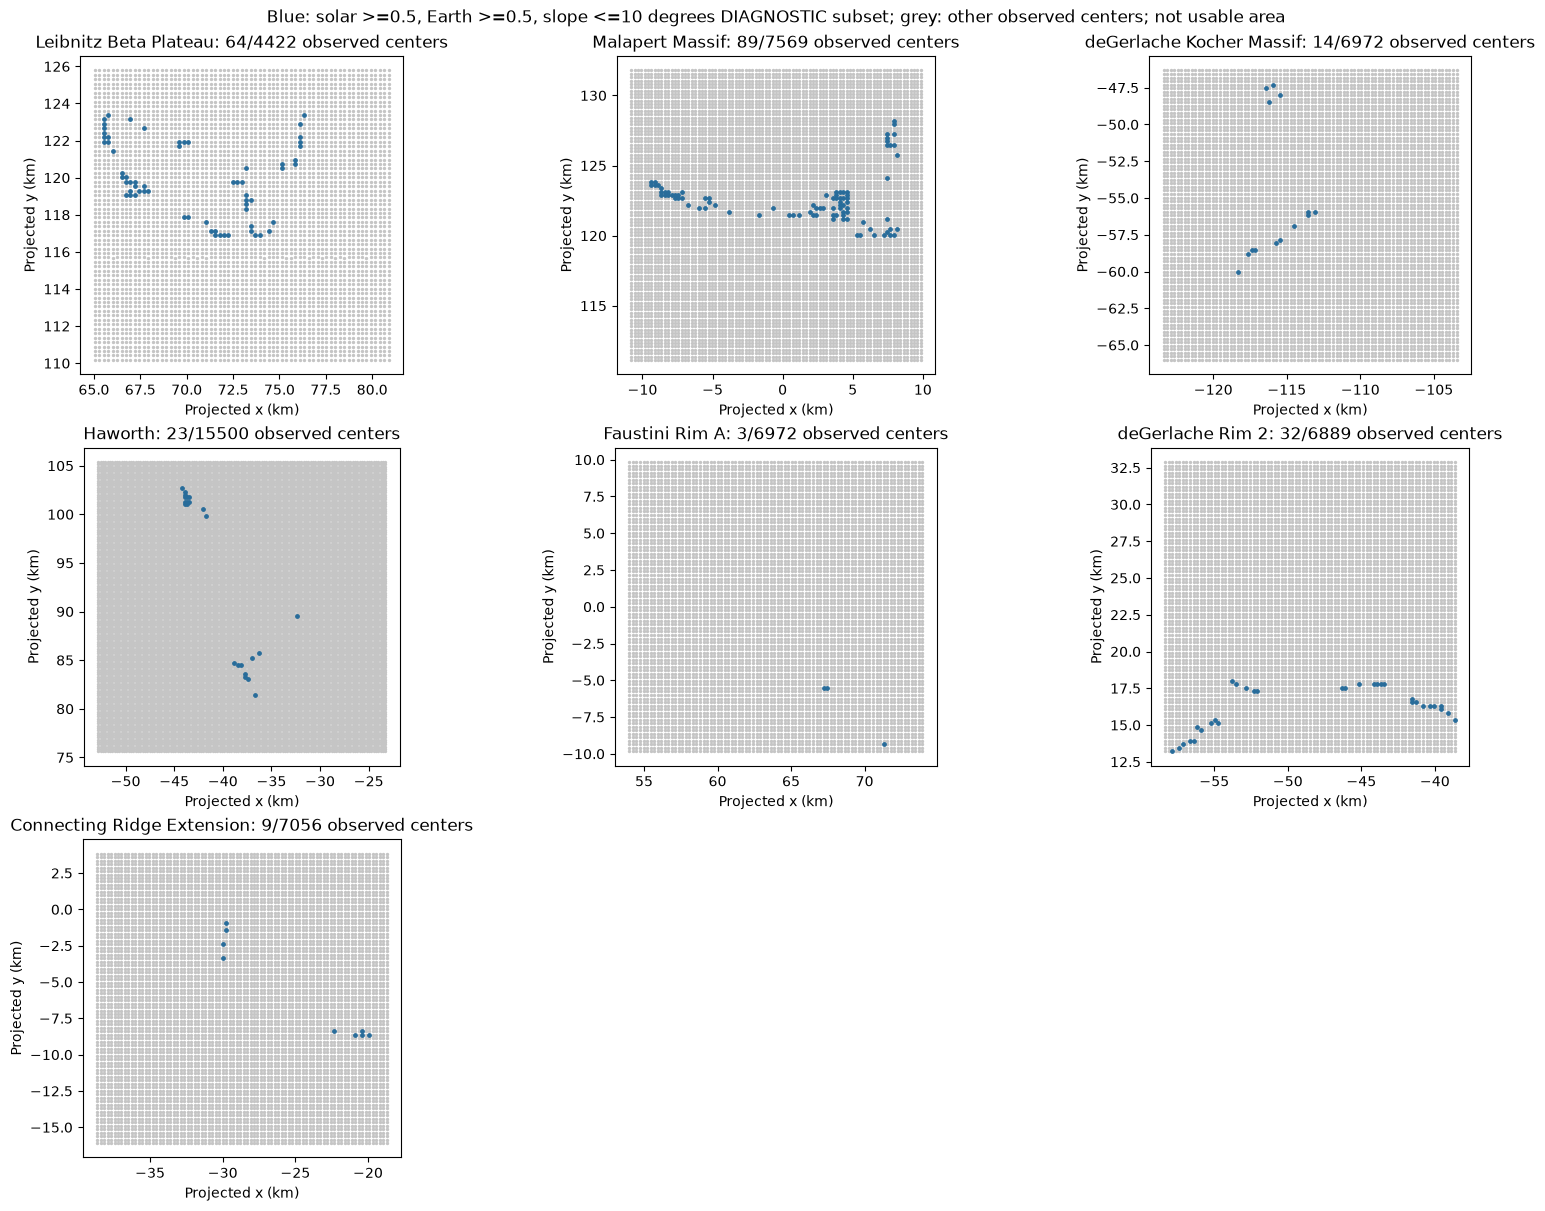

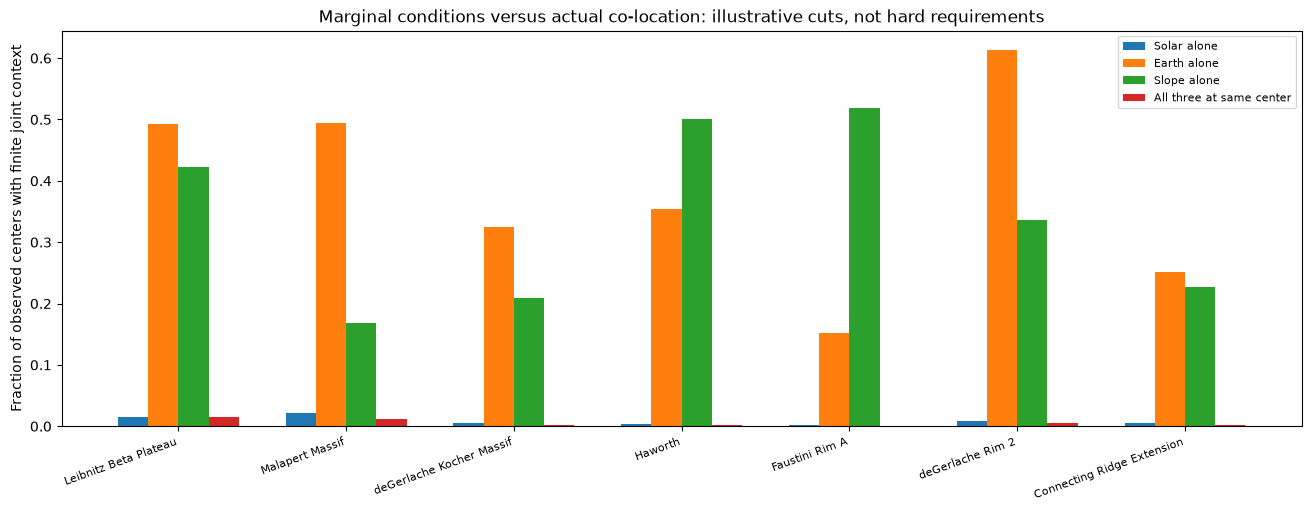

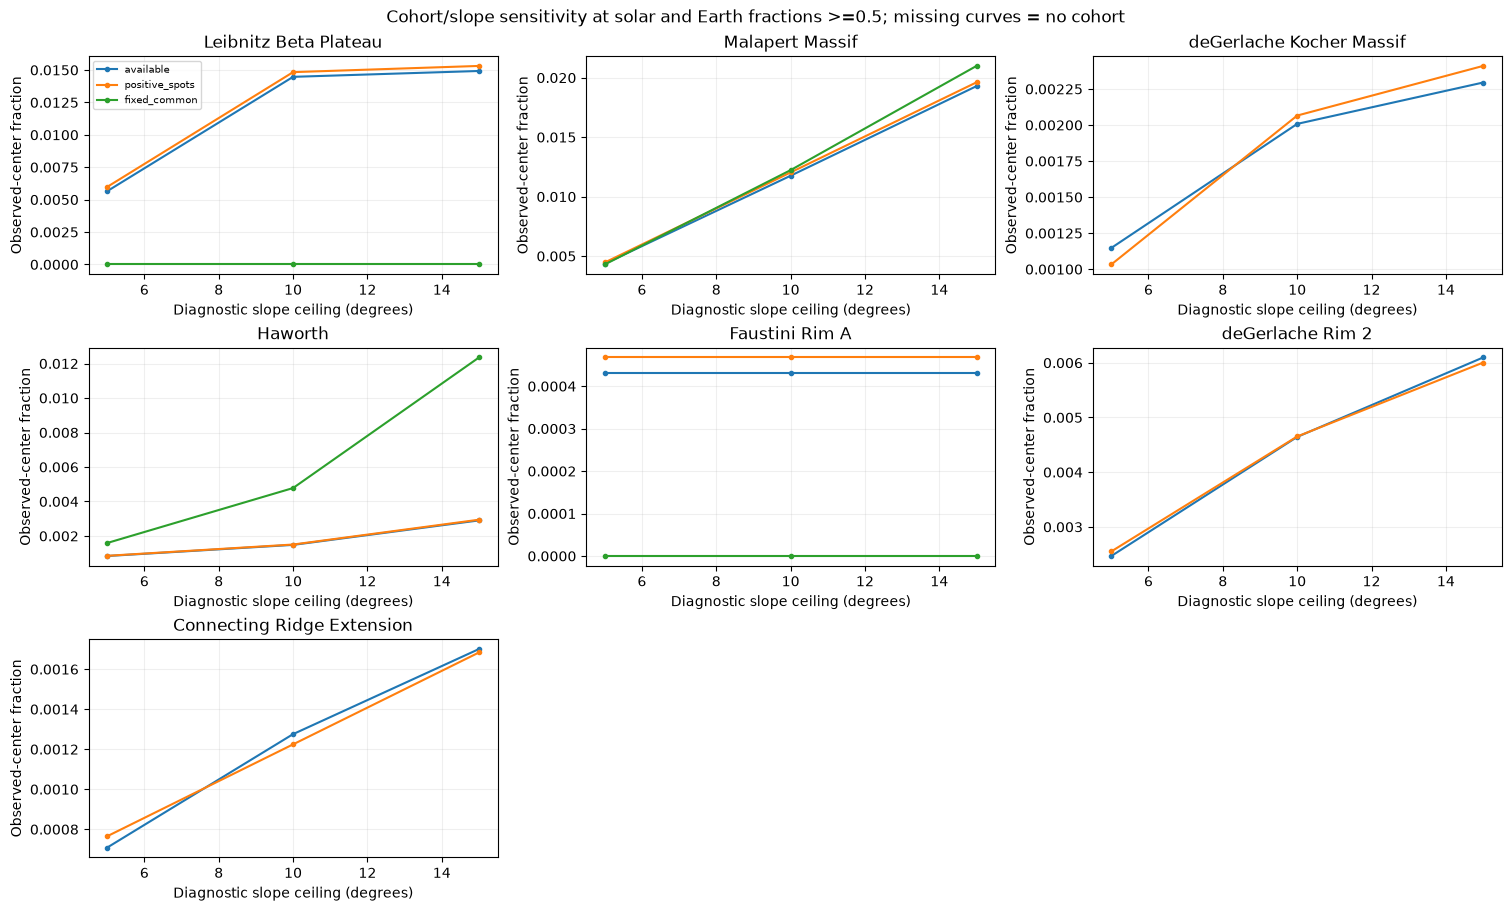

Leibnitz Beta Plateau 67213 common-product rows
Malapert Massif 126846 common-product rows
deGerlache Kocher Massif 79735 common-product rows
Haworth 224625 common-product rows
Faustini Rim A 78405 common-product rows
deGerlache Rim 2 87356 common-product rows
Connecting Ridge Extension 71699 common-product rows
Accepted local analysis/dar_005_research_radiation run: 20261107T160219935579Z_f7779c
Accepted local analysis/dar_015_battery_reference run: 20261109T142515683003Z_80acac
Accepted local analysis/dar_016_apollo_soil_reference run: 20261106T160018461511Z_ac6ed4
Accepted local analysis/dar_007_research_seismic run: 20261107T160226955774Z_fe01f4


C:\Users\silen\AppData\Local\Temp\ipykernel_27720\680985431.py:116: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  'available_cohort_scenarios_with_marginals_but_no_joint':int(sweeps.loc[sweeps.cohort.eq('available'),'marginals_exist_but_joint_absent'].fillna(False).sum()),


{'regions': 7,
 'diagnostic_sweep_rows': 567,
 'illustrative_conditions': (0.5, 0.5, 10.0),
 'illustrative_region_counts': [{'region': 'A3CLR22_10_Leibnitz_Beta_Plateau',
   'finite_joint_centers': 4422,
   'joint_centers': 64,
   'joint_observed_center_fraction': 0.014473089099954772,
   'marginal_min_fraction_upper_bound': 0.015151515151515152},
  {'region': 'A3CLR22_11_Malapert_Massif',
   'finite_joint_centers': 7569,
   'joint_centers': 89,
   'joint_observed_center_fraction': 0.011758488571806051,
   'marginal_min_fraction_upper_bound': 0.021931562954155107},
  {'region': 'A3CLR22_12_deGerlache_Kocher_Massif',
   'finite_joint_centers': 6972,
   'joint_centers': 14,
   'joint_observed_center_fraction': 0.002008032128514056,
   'marginal_min_fraction_upper_bound': 0.0051635111876075735},
  {'region': 'A3CLR22_2_Haworth',
   'finite_joint_centers': 15500,
   'joint_centers': 23,
   'joint_observed_center_fraction': 0.0014838709677419354,
   'marginal_min_fraction_upper_bound': 0.00

,region,cohort,solar_min,earth_min,slope_max_deg,cohort_centers,finite_joint_centers,unknown_context_centers,solar_condition_centers,earth_condition_centers,slope_condition_centers,solar_earth_centers,solar_slope_centers,earth_slope_centers,joint_centers,joint_observed_center_fraction,marginal_min_fraction_upper_bound,marginals_exist_but_joint_absent,status
13,A3CLR22_10_Leibnitz_Beta_Plateau,available,0.5,0.5,10.0,4422,4422,0,67,2176,1866,66,65,1511,64,0.014473,0.015152,False,diagnostic_only
40,A3CLR22_10_Leibnitz_Beta_Plateau,positive_spots,0.5,0.5,10.0,4179,4179,0,65,2083,1799,64,63,1456,62,0.014836,0.015554,False,diagnostic_only
67,A3CLR22_10_Leibnitz_Beta_Plateau,fixed_common,0.5,0.5,10.0,84,84,0,0,23,24,0,0,13,0,0.000000,0.000000,False,diagnostic_only
94,A3CLR22_11_Malapert_Massif,available,0.5,0.5,10.0,7569,7569,0,166,3738,1271,164,90,541,89,0.011758,0.021932,False,diagnostic_only
121,A3CLR22_11_Malapert_Massif,positive_spots,0.5,0.5,10.0,7395,7395,0,165,3599,1258,163,90,529,89,0.012035,0.022312,False,diagnostic_only
148,A3CLR22_11_Malapert_Massif,fixed_common,0.5,0.5,10.0,6051,6051,0,146,3642,910,144,75,501,74,0.012229,0.024128,False,diagnostic_only
175,A3CLR22_12_deGerlache_Kocher_Massif,available,0.5,0.5,10.0,6972,6972,0,36,2262,1452,16,33,335,14,0.002008,0.005164,False,diagnostic_only
202,A3CLR22_12_deGerlache_Kocher_Massif,positive_spots,0.5,0.5,10.0,5809,5809,0,32,1875,1263,14,29,297,12,0.002066,0.005509,False,diagnostic_only
229,A3CLR22_12_deGerlache_Kocher_Massif,fixed_common,0.5,0.5,10.0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,<NA>,no_finite_cohort
256,A3CLR22_2_Haworth,available,0.5,0.5,10.0,15500,15500,0,66,5483,7755,61,28,3228,23,0.001484,0.004258,False,diagnostic_only


count     median  \
region                               cohort                             
A3CLR22_10_Leibnitz_Beta_Plateau     available          17   9.806912   
                                     fixed_common        0        NaN   
                                     positive_spots     17   9.896461   
A3CLR22_11_Malapert_Massif           available          17  24.695816   
                                     fixed_common       17  -2.485649   
                                     positive_spots     17  22.801697   
A3CLR22_12_deGerlache_Kocher_Massif  available          16  77.816566   
                                     fixed_common        0        NaN   
                                     positive_spots     16  74.287503   
A3CLR22_2_Haworth                    available          17  49.048568   
                                     fixed_common       17  17.964226   
                                     positive_spots     17  48.922836   
A3CLR22_3_Faustini_Rim_A             available          11  84.074860   
                                     fixed_common        0        NaN   
                                     positive_spots     11  84.375688   
A3CLR22_4_deGerlache_Rim_2           available          16   1.280029   
                                     fixed_common        0        NaN   
                                     positive_spots     16   0.395706   
A3CLR22_5_Connecting_Ridge_Extension available          16  45.252366   
                                     fixed_common        0        NaN   
                                     positive_spots     16  42.681444   

                                                           min         max  
region                               cohort                                 
A3CLR22_10_Leibnitz_Beta_Plateau     available       -3.288178  108.756020  
                                     fixed_common          NaN         NaN  
                                     positive_spots  -2.938168  107.541759  
A3CLR22_11_Malapert_Massif           available      -12.474175   94.922280  
                                     fixed_common   -43.242317   56.625458  
                                     positive_spots -12.461472  109.069252  
A3CLR22_12_deGerlache_Kocher_Massif  available      -12.325469  136.651435  
                                     fixed_common          NaN         NaN  
                                     positive_spots -12.009102  136.974090  
A3CLR22_2_Haworth                    available        5.810493  136.276344  
                                     fixed_common     2.503467   90.223884  
                                     positive_spots   5.814702  136.297157  
A3CLR22_3_Faustini_Rim_A             available       -4.450218  145.558349  
                                     fixed_common          NaN         NaN  
                                     positive_spots  -4.216248  146.183686  
A3CLR22_4_deGerlache_Rim_2           available      -30.956650  114.404556  
                                     fixed_common          NaN         NaN  
                                     positive_spots -32.142319  114.508106  
A3CLR22_5_Connecting_Ridge_Extension available      -56.377678  132.282512  
                                     fixed_common          NaN         NaN  
                                     positive_spots -55.928405  136.515801

,region,criterion_input,metric,value,unit,finite_centers,spatial_support,temporal_support,evidence_role,rule_classification,requirement_status,reason_code,preference_score,support_count,support_type,source_profile_run
0,A3CLR22_10_Leibnitz_Beta_Plateau,solar_context,solar_visibility_median,0.260120,fraction,4422.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,4422,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
1,A3CLR22_11_Malapert_Massif,solar_context,solar_visibility_median,0.379840,fraction,7569.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,7569,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
2,A3CLR22_12_deGerlache_Kocher_Massif,solar_context,solar_visibility_median,0.240720,fraction,6972.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,6972,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
3,A3CLR22_2_Haworth,solar_context,solar_visibility_median,0.237560,fraction,15500.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,15500,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
4,A3CLR22_3_Faustini_Rim_A,solar_context,solar_visibility_median,0.158380,fraction,6972.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,6972,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
5,A3CLR22_4_deGerlache_Rim_2,solar_context,solar_visibility_median,0.350240,fraction,6889.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,6889,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
6,A3CLR22_5_Connecting_Ridge_Extension,solar_context,solar_visibility_median,0.247600,fraction,7056.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,7056,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
7,A3CLR22_10_Leibnitz_Beta_Plateau,earth_visibility_context,earth_visibility_median,0.485200,fraction,4422.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,4422,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
8,A3CLR22_11_Malapert_Massif,earth_visibility_context,earth_visibility_median,0.437720,fraction,7569.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,7569,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...
9,A3CLR22_12_deGerlache_Kocher_Massif,earth_visibility_context,earth_visibility_median,0.294360,fraction,6972.0,observed regional thermal-center union; not ar...,static modeled context; not mission-time history,region_associated_context,Unconfigured,Unknown,MISSION_OR_POLICY_NOT_CONFIGURED,NaN,6972,distinct observed centers,env_algo_task\data\processed\analysis\dar_017_l...


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\env_algo_task\data\processed\analysis\dar_018_joint_base_environment\20261109T142728281806Z_0c5c4c


In [2]:
REGION_LIMIT=None  # Use 1 for a representative first execution, None for all seven regions.
PROFILE_RUN_ID=None
SOLAR_THRESHOLDS=[.25,.5,.75]
EARTH_THRESHOLDS=[.25,.5,.75]
SLOPE_THRESHOLDS_DEG=[5.,10.,15.]
ILLUSTRATIVE_CONDITIONS=(.5,.5,10.)  # Diagnostic illustration only; NOT adopted mission rules.
profile=latest_completed_run(ROOT,'analysis/dar_017_lunar_site_profiles',PROFILE_RUN_ID)
profile_config=json.loads((profile/'provenance.json').read_text())['config']
joint=(ROOT/profile_config['joint_run']).resolve()
environment=(ROOT/json.loads((joint/'provenance.json').read_text())['config']['environment_run']).resolve()
with Run(ROOT,'analysis/dar_018_joint_base_environment',{'profile_run':str(profile.relative_to(ROOT)),
    'joint_run':str(joint.relative_to(ROOT)),'environment_run':str(environment.relative_to(ROOT)),
    'region_limit':REGION_LIMIT,'solar_diagnostic_grid':SOLAR_THRESHOLDS,'earth_diagnostic_grid':EARTH_THRESHOLDS,
    'slope_diagnostic_grid_deg':SLOPE_THRESHOLDS_DEG,'illustrative_conditions':ILLUSTRATIVE_CONDITIONS,
    'adopted_operational_thresholds':None,'preference_weights':None},'Moon/Site_Assessment/Dar_018_joint_environment_terrain_tradeoffs.ipynb') as run:
    run.input(Path(site_comparison.__file__));run.input(Path(decision_eda.__file__))
    centers=pd.read_csv(accepted_input(run,joint,'native_center_context.csv.gz'))
    source_profiles=pd.read_csv(accepted_input(run,profile,'regional_static_profiles.csv'))
    thermal_profiles_source=pd.read_csv(accepted_input(run,profile,'common_product_thermal_profiles.csv'))
    contract=json.loads(accepted_input(run,profile,'comparison_contract.json').read_text())
    regions=sorted(source_profiles.region.unique())
    if REGION_LIMIT is not None:
        if type(REGION_LIMIT) is not int or not 1<=REGION_LIMIT<=len(regions):raise ValueError('Invalid region sample')
        regions=regions[:REGION_LIMIT]
    centers=centers.loc[centers.region.isin(regions)].copy();source_profiles=source_profiles.loc[source_profiles.region.isin(regions)]
    products=contract['common_products']
    sweeps=joint_sweep(centers,SOLAR_THRESHOLDS,EARTH_THRESHOLDS,SLOPE_THRESHOLDS_DEG)
    sweeps.to_csv(run.path('joint_condition_sweep.csv'),index=False)
    solar,earth,slope=ILLUSTRATIVE_CONDITIONS
    benchmark=sweeps.loc[sweeps.solar_min.eq(solar)&sweeps.earth_min.eq(earth)&sweeps.slope_max_deg.eq(slope)].copy()
    benchmark.to_csv(run.path('illustrative_joint_conditions.csv'),index=False)
    fig,axes=plt.subplots(int(np.ceil(len(regions)/3)),3,figsize=(16,max(4,int(np.ceil(len(regions)/3))*4)),squeeze=False,layout='constrained')
    for ax,region in zip(axes.flat,regions):
        p=centers.loc[centers.region.eq(region)];state=joint_state(p,solar,earth,slope)
        other=p.loc[state.eq(False)];selected=p.loc[state.eq(True)]
        ax.scatter(other.x_m/1000,other.y_m/1000,s=2,color='#c5c5c5')
        ax.scatter(selected.x_m/1000,selected.y_m/1000,s=6,color='#286c9a')
        ax.set(title=f'{short(region)}: {len(selected)}/{len(p)} observed centers',xlabel='Projected x (km)',ylabel='Projected y (km)');ax.set_aspect('equal')
    for ax in list(axes.flat)[len(regions):]:ax.set_visible(False)
    fig.suptitle('Blue: solar >=0.5, Earth >=0.5, slope <=10 degrees DIAGNOSTIC subset; grey: other observed centers; not usable area')
    savefig(run,fig,'illustrative_joint_center_maps')
    fig,ax=plt.subplots(figsize=(13,5),layout='constrained')
    p=benchmark.loc[benchmark.cohort.eq('available')].set_index('region').loc[regions]
    for shift,column,label in [(-.27,'solar_condition_centers','Solar alone'),(-.09,'earth_condition_centers','Earth alone'),
                               (.09,'slope_condition_centers','Slope alone'),(.27,'joint_centers','All three at same center')]:
        ax.bar(np.arange(len(regions))+shift,p[column]/p.finite_joint_centers,width=.18,label=label)
    ax.set_xticks(range(len(regions)),[short(x) for x in regions],rotation=20,ha='right',fontsize=8)
    ax.set(ylabel='Fraction of observed centers with finite joint context',title='Marginal conditions versus actual co-location: illustrative cuts, not hard requirements')
    ax.legend(fontsize=8);savefig(run,fig,'marginal_versus_joint_conditions')
    fig,axes=plt.subplots(int(np.ceil(len(regions)/3)),3,figsize=(15,max(3,int(np.ceil(len(regions)/3))*3)),squeeze=False,layout='constrained')
    for ax,region in zip(axes.flat,regions):
        for cohort in COHORTS:
            p=sweeps.loc[sweeps.region.eq(region)&sweeps.cohort.eq(cohort)&sweeps.solar_min.eq(solar)&sweeps.earth_min.eq(earth)]
            ax.plot(p.slope_max_deg,p.joint_observed_center_fraction,marker='.',label=cohort)
        ax.set(title=short(region),xlabel='Diagnostic slope ceiling (degrees)',ylabel='Observed-center fraction');ax.grid(alpha=.2)
    for ax in list(axes.flat)[len(regions):]:ax.set_visible(False)
    axes.flat[0].legend(fontsize=7);fig.suptitle('Cohort/slope sensitivity at solar and Earth fractions >=0.5; missing curves = no cohort')
    savefig(run,fig,'diagnostic_cohort_sensitivity')
    thermal_parts=[]
    columns=['region','source_product','clon','clat','tbol','usable','complete_common_cohort']
    for region in regions:
        path=accepted_input(run,environment,'paired_observations/'+region+'.csv.gz')
        pieces=[]
        for chunk in pd.read_csv(path,usecols=columns,chunksize=200_000):
            if not chunk.region.eq(region).all():raise ValueError('Source region mismatch')
            chosen=chunk.loc[chunk.source_product.isin(products)]
            if len(chosen):pieces.append(chosen)
        if not pieces:raise ValueError('Expected common-product observations are absent')
        observations=pd.concat(pieces,ignore_index=True)
        part=thermal_joint_summary(observations,centers.loc[centers.region.eq(region)],products,ILLUSTRATIVE_CONDITIONS)
        thermal_parts.append(part);print(short(region),int(part.loc[part.cohort.eq('available'),'usable_rows'].sum()),'common-product rows')
        del observations,pieces
    thermal=pd.concat(thermal_parts,ignore_index=True);thermal.to_csv(run.path('joint_thermal_product_context.csv'),index=False)
    keys=['region','cohort','source_product']
    a=thermal.loc[thermal.condition_class.eq('joint_subset')].drop(columns='condition_class')
    b=thermal.loc[thermal.condition_class.eq('other_measured_context')].drop(columns='condition_class')
    contrasts=a.merge(b,on=keys,suffixes=('_joint','_other'),validate='one_to_one')
    contrasts['joint_minus_other_median_K']=contrasts.tbol_median_K_joint-contrasts.tbol_median_K_other
    contrasts['comparison_status']=np.where(contrasts.joint_minus_other_median_K.notna(),'both_groups_observed','one_or_both_groups_absent')
    contrasts.to_csv(run.path('matched_product_joint_temperature_contrasts.csv'),index=False)
    contrasts.groupby(['region','cohort']).joint_minus_other_median_K.agg(['count','median','min','max']).to_csv(run.path('joint_temperature_contrast_summary.csv'))
    rules=rule_input_table(source_profiles)
    rules['support_count']=rules.finite_centers;rules['support_type']='distinct observed centers'
    additional=[]
    for row in thermal_profiles_source.loc[thermal_profiles_source.cohort.eq('available')&thermal_profiles_source.region.isin(regions)].itertuples():
        additional.append({'region':row.region,'criterion_input':'thermal_phase_context',
            'metric':'median_of_common_product_medians_K','value':row.median_of_product_medians_K,'unit':'K',
            'finite_centers':np.nan,'support_count':row.supported_common_products,'support_type':'phase products',
            'spatial_support':'regional available thermal-center cohorts; locations can change by phase',
            'temporal_support':'matched cumulative phase averages; not mission-time exposure',
            'evidence_role':'region_associated_context','rule_classification':'Unconfigured','requirement_status':'Unknown',
            'reason_code':'MISSION_OR_POLICY_NOT_CONFIGURED','preference_score':np.nan})
    rules=pd.concat([rules,pd.DataFrame(additional)],ignore_index=True)
    rules['source_profile_run']=str(profile.relative_to(ROOT));rules.to_csv(run.path('environmental_rule_inputs.csv'),index=False)
    broader=[]
    for ids,stage,role,reason in [
        ('D07/D08/D31','analysis/dar_005_research_radiation','broader radiation/study context','No validated per-site surface dose or project shielding model'),
        ('R01','analysis/dar_015_battery_reference','laboratory reference','Not the selected mission battery or site-specific environment'),
        ('R02','analysis/dar_016_apollo_soil_reference','historical non-polar reference','Not local polar soil properties or wheel/foundation response'),
        ('D13/D14','analysis/dar_007_research_seismic','historical seismic context','No validated polar-site structural response or recurrence model')]:
        source=latest_completed_run(ROOT,stage);accepted_input(run,source,'findings.json')
        broader.append({'dataset_ids':ids,'evidence_role':role,'source_run':str(source.relative_to(ROOT)),
            'scope':'not assigned fabricated local numeric values','local_rule_value':np.nan,'requirement_status':'Unknown','reason':reason})
    pd.DataFrame(broader).to_csv(run.path('broader_reference_evidence.csv'),index=False)
    policy={'diagnostic_solar_thresholds':SOLAR_THRESHOLDS,'diagnostic_earth_thresholds':EARTH_THRESHOLDS,
        'diagnostic_slope_thresholds_deg':SLOPE_THRESHOLDS_DEG,'illustration':ILLUSTRATIVE_CONDITIONS,
        'operational_adoption':False,'preference_weights':None,'cohorts':list(COHORTS),
        'denominator':'distinct observed centers with all three finite context fields in the stated cohort',
        'comparison':'same region and product for thermal contrasts; not a causal illumination effect',
        'critical_limits':['Fractions are not measured usable land area','Static visibility fields are not simultaneous time histories',
            'No base footprint, hard threshold, numerical confidence probability or suitability ranking invented']}
    run.path('diagnostic_and_rule_contract.json').write_text(json.dumps(policy,indent=2),encoding='utf-8')
    findings(run,{'regions':len(regions),'diagnostic_sweep_rows':len(sweeps),'illustrative_conditions':ILLUSTRATIVE_CONDITIONS,
        'illustrative_region_counts':benchmark.loc[benchmark.cohort.eq('available'),['region','finite_joint_centers','joint_centers',
            'joint_observed_center_fraction','marginal_min_fraction_upper_bound']].to_dict('records'),
        'available_cohort_scenarios_with_marginals_but_no_joint':int(sweeps.loc[sweeps.cohort.eq('available'),'marginals_exist_but_joint_absent'].fillna(False).sum()),
        'thermal_context_rows':len(thermal),'comparable_joint_other_products':int(contrasts.joint_minus_other_median_K.notna().sum()),
        'numeric_rule_input_rows':len(rules),'broader_reference_records':len(broader),'operational_scores_computed':0,
        'limits':policy['critical_limits']})
    display(benchmark);display(contrasts.groupby(['region','cohort']).joint_minus_other_median_K.agg(['count','median','min','max']));display(rules)
OUT=run.directory;print('Completed:',OUT)


## Pipeline use
The new inputs support explicit feature lookup, scope/quality checks, criterion configuration and explained comparisons. Keep the diagnostic masks outside operational eligibility code until a justified policy exists. Use matching evidence and applicable response models for hard-rule evaluation; only mandatory passes permit preference ranking. Broader/reference evidence is not discarded merely for lacking a CNN-patch match, but cannot supply unsupported local values.